# Late Deliveries: Evidence and Decisions

This notebook presents the key findings from the QuickBite late-delivery prediction project, including model comparison, hyperparameter tuning, cost-based threshold selection, and final test results. It uses saved reports to present the analysis without retraining models or making new test predictions.

In [1]:
import io
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import FuncFormatter

plt.switch_backend("Agg")
ROOT = Path.cwd()
if not (ROOT / "reports" / "metrics.json").is_file():
    ROOT = ROOT.parent
assert (ROOT / "reports" / "metrics.json").is_file()
cv = pd.read_csv(ROOT / "reports" / "cv_results.csv")
tuning = pd.read_csv(ROOT / "reports" / "tuning_results.csv", keep_default_na=False)
thresholds = pd.read_csv(ROOT / "reports" / "threshold_results.csv")
leakage = pd.read_csv(ROOT / "reports" / "leakage_results.csv")
metrics = json.loads((ROOT / "reports" / "metrics.json").read_text())
model_info = json.loads((ROOT / "models" / "model_info.json").read_text())
assert metrics == model_info["test_results"]
assert model_info["best_parameters"] == {"model__C": 0.1, "model__class_weight": None}
assert metrics["threshold"] == 0.25


def dollars(value):
    """Format stored costs for human reading."""
    return f"${value:,.2f}"


def show_plot(figure):
    """Embed a real rendered PNG in this notebook without writing result files."""
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue()))
    plt.close(figure)


print("Loaded saved reports only; no model loading, fitting or predictions.")
print("Recorded scikit-learn version:", model_info["scikit_learn_version"])

Loaded saved reports only; no model loading, fitting or predictions.
Recorded scikit-learn version: 1.9.1


## Features and leakage prevention

The model uses five features treated as available when an order is placed: three numeric features (`distance_km`, `items`, `hour`) and two categorical features (`weather`, `day_type`).

We excluded `order_id` because it is an identifier, `prep_minutes` and `customer_rating` because they contain information unavailable at order placement, and `vehicle` and `courier_months` because courier assignment at that time is not confirmed. The target variable, `late`, was also excluded from the input features.

To prevent data leakage, we used a single scikit-learn Pipeline for preprocessing and modeling. Missing numeric values were filled with the median and standardized, while categorical features were one-hot encoded. All preprocessing steps were fitted separately within each training fold.

## Training late-delivery prevalence

Of the 2,250 training orders, 351 (15.6%) were delivered late, while 1,899 (84.4%) arrived on time. This shows that late deliveries are the minority class in our dataset.

In [2]:
training_rows = int(cv["training_rows"].iloc[0])
assert cv["training_rows"].nunique() == 1
zero_flag = thresholds.loc[thresholds["flagged_orders"] == 0]
assert not zero_flag.empty and zero_flag["missed_late_orders"].nunique() == 1
training_late = int(zero_flag["missed_late_orders"].iloc[0])
training_rate = training_late / training_rows
assert np.isclose(
    cv.loc[cv["model"] == "dummy", "accuracy_mean"].item(), 1 - training_rate
)
prevalence = pd.DataFrame(
    {
        "Training outcome": ["Late", "On time"],
        "Orders": [training_late, training_rows - training_late],
        "Share": [f"{training_rate:.1%}", f"{1 - training_rate:.1%}"],
    }
)
display(prevalence)
print(f"Training only: {training_late:,}/{training_rows:,} late ({training_rate:.1%}).")

,Training outcome,Orders,Share
0,Late,351,15.6%
1,On time,1899,84.4%


Training only: 351/2,250 late (15.6%).


## Training-only model comparison

Four models were evaluated using five-fold stratified cross-validation on the training data. The table below compares their mean performance and standard deviation across five metrics: accuracy, precision, recall, F1, and ROC-AUC.

In [3]:
labels = {
    "dummy": "DummyClassifier",
    "logistic_regression": "Logistic Regression",
    "random_forest": "Random Forest",
    "balanced_decision_tree": "Balanced Decision Tree",
}
metric_names = ["accuracy", "precision", "recall", "f1", "roc_auc"]
comparison_table = pd.DataFrame({"Model": cv["model"].map(labels)})
for metric in metric_names:
    comparison_table[metric] = [
        f"{mean:.6f} +/- {sd:.6f}"
        for mean, sd in zip(cv[f"{metric}_mean"], cv[f"{metric}_std"], strict=True)
    ]
display(comparison_table)

,Model,accuracy,precision,recall,f1,roc_auc
0,DummyClassifier,0.844000 +/- 0.000889,0.000000 +/- 0.000000,0.000000 +/- 0.000000,0.000000 +/- 0.000000,0.500000 +/- 0.000000
1,Logistic Regression,0.857778 +/- 0.005963,0.643570 +/- 0.067079,0.199356 +/- 0.019314,0.304262 +/- 0.029339,0.772782 +/- 0.035244
2,Random Forest,0.847556 +/- 0.013003,0.528010 +/- 0.079856,0.270543 +/- 0.039496,0.356063 +/- 0.048863,0.709683 +/- 0.035158
3,Balanced Decision Tree,0.779111 +/- 0.018249,0.292070 +/- 0.039569,0.284789 +/- 0.031390,0.287356 +/- 0.032076,0.578922 +/- 0.019925


Logistic Regression was selected because it achieved the highest ROC-AUC (0.772782) and precision (0.643570) among the real models. Although Random Forest showed higher recall and F1, ROC-AUC was prioritized to evaluate model discrimination before selecting a cost-based threshold. The final threshold was chosen separately to balance voucher costs (USD 4.00) and missed-delay costs (USD 15.00).

## Training-only hyperparameter tuning

We used GridSearchCV with five-fold stratified cross-validation to tune Logistic Regression. Eight combinations of C (0.01, 0.1, 1, 10) and class_weight (None, balanced) were evaluated using ROC-AUC. Different C values control regularization strength, while balanced class weights give more importance to the minority class. ROC-AUC was chosen because the final decision threshold would be selected separately based on business costs.

In [4]:
tuning_display = tuning[
    ["C", "class_weight", "roc_auc_mean", "roc_auc_std", "rank"]
].copy()
tuning_display["roc_auc_mean"] = tuning_display["roc_auc_mean"].map(
    lambda x: f"{x:.9f}"
)
tuning_display["roc_auc_std"] = tuning_display["roc_auc_std"].map(lambda x: f"{x:.9f}")
display(tuning_display)
best = tuning.loc[tuning["rank"] == 1].iloc[0]
baseline = cv.loc[cv["model"] == "logistic_regression"].iloc[0]
gain = best["roc_auc_mean"] - baseline["roc_auc_mean"]
print(f"Best: C={best['C']:g}, class_weight={best['class_weight']}")
print(
    f"Untuned AUC: {baseline['roc_auc_mean']:.9f}; "
    f"tuned AUC: {best['roc_auc_mean']:.9f}"
)
print(f"Improvement: {gain:.9f}; best fold SD: {best['roc_auc_std']:.9f}")

,C,class_weight,roc_auc_mean,roc_auc_std,rank
0,0.01,None,0.771181947,0.037937429,8
1,0.01,balanced,0.771657790,0.036849329,7
2,0.10,None,0.772862258,0.035305596,1
3,0.10,balanced,0.771958966,0.035514827,6
4,1.00,None,0.772781796,0.035244026,2
5,1.00,balanced,0.772102601,0.035296338,4
6,10.00,None,0.772556578,0.035357252,3
7,10.00,balanced,0.772050314,0.035274035,5


Best: C=0.1, class_weight=None
Untuned AUC: 0.772781796; tuned AUC: 0.772862258
Improvement: 0.000080462; best fold SD: 0.035305596


The best configuration was C=0.1 and class_weight=None, with a mean ROC-AUC of 0.772862 compared to 0.772782 before tuning. However, the improvement (0.000080462) was very small relative to the fold standard deviation (approximately 0.035). Therefore, tuning did not demonstrate a clear performance improvement.

## Customer-rating leakage demonstration

Only customer_rating was added in a separate training-only experiment, using Stage 4's original four candidates and identical folds. The logistic comparison uses C=1.0, not the final C=0.1. Rating is post-delivery and depends on late status; it is unavailable at placement. Even fold-local median imputation cannot remove information about the outcome already present in validation-row ratings. Inflated scores do not describe legitimate order-time prediction performance, and did not change the final model, features or threshold.

In [5]:
leakage_display = pd.DataFrame({"Model": leakage["model"].map(labels)})
for variant in ["clean", "leakage"]:
    leakage_display[f"{variant} AUC mean +/- SD"] = [
        f"{mean:.6f} +/- {sd:.6f}"
        for mean, sd in zip(
            leakage[f"{variant}_roc_auc_mean"],
            leakage[f"{variant}_roc_auc_std"],
            strict=True,
        )
    ]
leakage_display["AUC difference"] = leakage["roc_auc_difference"].map(
    lambda x: f"{x:+.6f}"
)
display(leakage_display)

,Model,clean AUC mean +/- SD,leakage AUC mean +/- SD,AUC difference
0,DummyClassifier,0.500000 +/- 0.000000,0.500000 +/- 0.000000,+0.000000
1,Logistic Regression,0.772782 +/- 0.035244,0.905277 +/- 0.011620,+0.132495
2,Random Forest,0.709683 +/- 0.035158,0.871095 +/- 0.023243,+0.161412
3,Balanced Decision Tree,0.578922 +/- 0.019925,0.734536 +/- 0.035949,+0.155614


## Training OOF cost curve and approved threshold

Cost = USD 4.00 per flagged order plus USD 15.00 per unflagged actual delay. Class-1 OOF probabilities came from cross_val_predict(method="predict_proba") with the full C=0.1 logistic pipeline and the same five stratified folds. The completed search evaluated exactly 19 thresholds, 0.05 through 0.95 by 0.05, flagging probability >=threshold and choosing the lowest threshold for tied minimum costs.

The approved 0.25 threshold is read from saved final metadata here. The following curve is threshold-selection evidence on training labels, not an independent performance estimate. Hyperparameters also used training data; OOF alone does not eliminate selection optimism.

,threshold,flagged_orders,missed_late_orders,total_cost
0,0.05,1886,16,"$7,784.00"
1,0.10,1173,67,"$5,697.00"
2,0.15,757,111,"$4,693.00"
3,0.20,518,151,"$4,337.00"
4,0.25,374,180,"$4,196.00"
5,0.30,276,211,"$4,269.00"
6,0.35,211,236,"$4,384.00"
7,0.40,161,259,"$4,529.00"
8,0.45,123,274,"$4,602.00"
9,0.50,100,285,"$4,675.00"


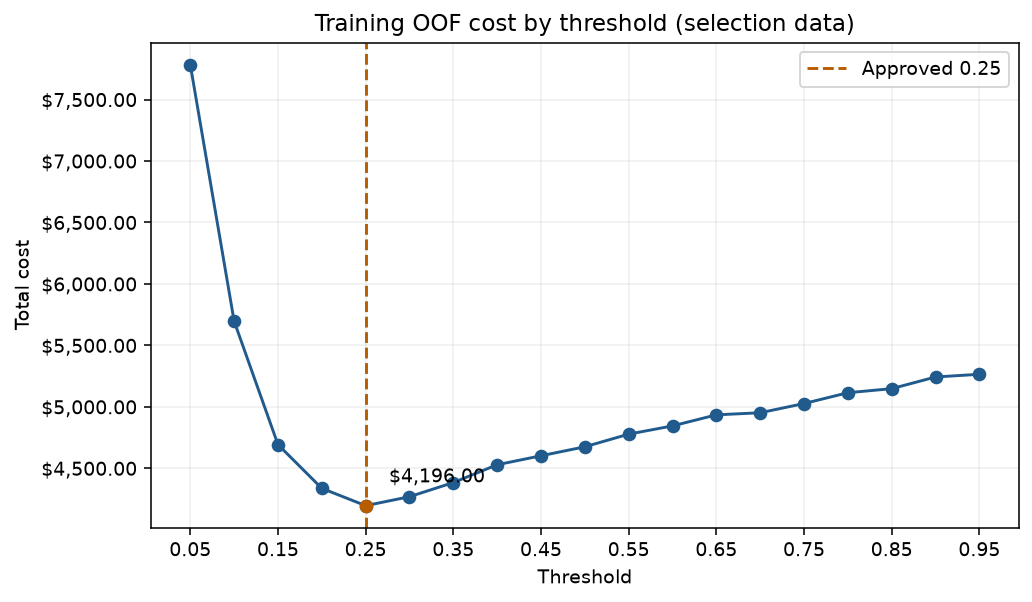

In [6]:
approved_threshold = metrics["threshold"]
chosen = thresholds.loc[np.isclose(thresholds["threshold"], approved_threshold)].iloc[0]
assert len(thresholds) == 19
assert chosen["total_cost"] == thresholds["total_cost"].min()
assert (
    thresholds["total_cost"]
    == 4 * thresholds["flagged_orders"] + 15 * thresholds["missed_late_orders"]
).all()
threshold_display = thresholds.copy()
threshold_display["threshold"] = threshold_display["threshold"].map(
    lambda x: f"{x:.2f}"
)
threshold_display["total_cost"] = threshold_display["total_cost"].map(dollars)
display(threshold_display)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(thresholds["threshold"], thresholds["total_cost"], marker="o", color="#215a8c")
ax.axvline(
    approved_threshold,
    color="#b85c00",
    linestyle="--",
    label=f"Approved {approved_threshold:.2f}",
)
ax.scatter([approved_threshold], [chosen["total_cost"]], color="#b85c00", zorder=3)
ax.annotate(
    dollars(chosen["total_cost"]),
    (approved_threshold, chosen["total_cost"]),
    xytext=(12, 12),
    textcoords="offset points",
)
ax.set(
    title="Training OOF cost by threshold (selection data)",
    xlabel="Threshold",
    ylabel="Total cost",
)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: dollars(value)))
ax.set_xticks(np.arange(0.05, 1, 0.1))
ax.grid(alpha=0.2)
ax.legend()
show_plot(fig)

## Saved final test result

The final 750-order holdout was evaluated after fixing all decisions. The matrix and metrics below are loaded from metrics.json. This notebook never predicts or re-evaluates held-out rows. Confusion matrix rows are actual [0,1], columns are predicted [0,1]; AUC was computed from probabilities, not these binary decisions.

Saved test: 750 orders, 117 actually late; threshold 0.25.


,Metric,Saved value
0,Precision,0.427273
1,Recall,0.401709
2,F1,0.414097
3,ROC-AUC,0.752238


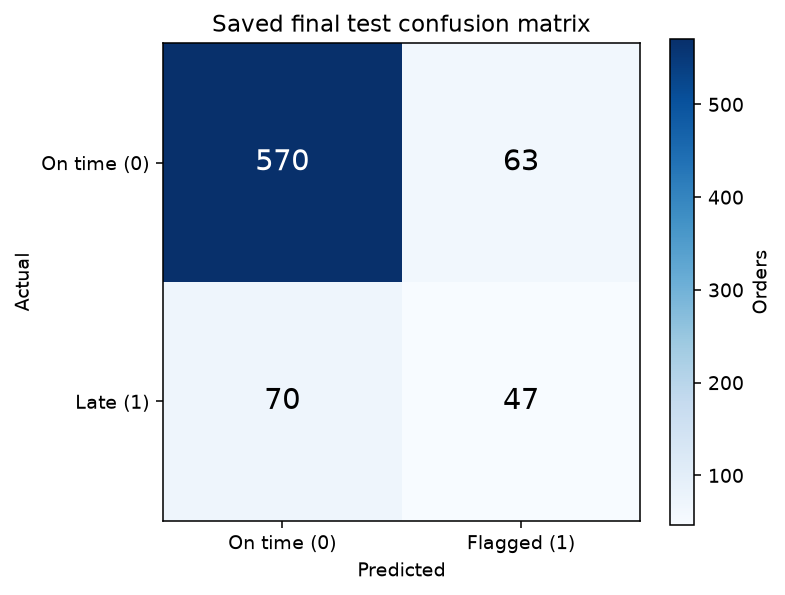

In [7]:
matrix = np.array(metrics["confusion_matrix"])
tn, fp = matrix[0]
fn, tp = matrix[1]
assert matrix.sum() == metrics["n_orders"]
assert fp + tp == metrics["flagged_orders"] and fn == metrics["missed_late_orders"]
print(
    f"Saved test: {metrics['n_orders']:,} orders, {fn + tp} actually late; "
    f"threshold {approved_threshold:.2f}."
)
display(
    pd.DataFrame(
        {
            "Metric": ["Precision", "Recall", "F1", "ROC-AUC"],
            "Saved value": [
                f"{metrics[key]:.6f}"
                for key in ["precision", "recall", "f1", "roc_auc"]
            ],
        }
    )
)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(matrix, cmap="Blues")
for (i, j), value in np.ndenumerate(matrix):
    ax.text(
        j,
        i,
        str(value),
        ha="center",
        va="center",
        fontsize=15,
        color="white" if value > matrix.max() / 2 else "black",
    )
ax.set(
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=["On time (0)", "Flagged (1)"],
    yticklabels=["On time (0)", "Late (1)"],
    xlabel="Predicted",
    ylabel="Actual",
    title="Saved final test confusion matrix",
)
fig.colorbar(image, ax=ax, label="Orders")
show_plot(fig)

## Three policies: selection evidence versus final test

Training OOF and final test costs have different sample sizes and roles. Only final test results estimate the frozen policy on held-out orders. Comparing their total dollars directly as if sample sizes matched would be misleading. All money values below are displayed to two decimals.

,Policy,"Training OOF (2,250 orders)",Final test (750 orders)
0,Flag nobody,"$5,265.00","$1,755.00"
1,Flag everybody,"$9,000.00","$3,000.00"
2,Model,"$4,196.00","$1,490.00"


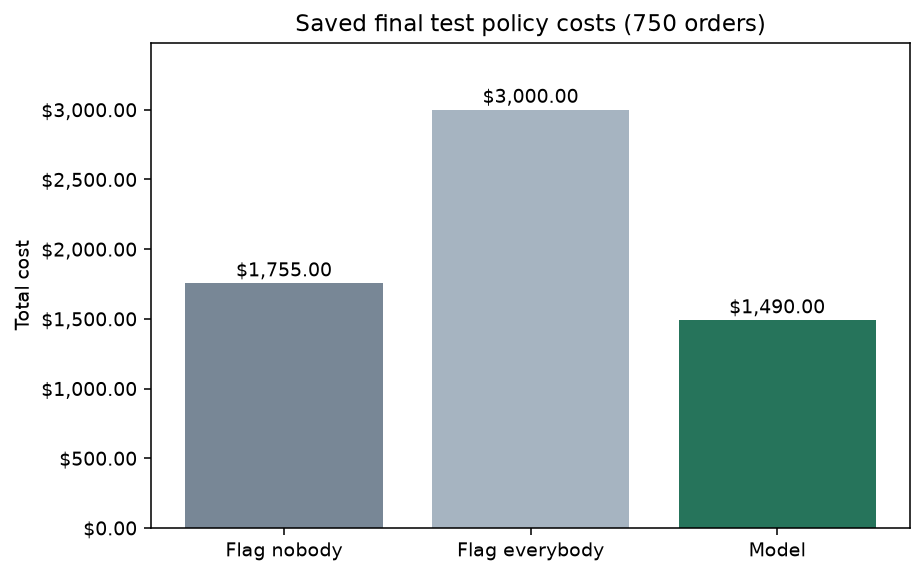

Observed saving vs nobody: $265.00 (15.10%).
Missed late orders: 70 of 117.


In [8]:
policy_names = ["Flag nobody", "Flag everybody", "Model"]
training_costs = [15 * training_late, 4 * training_rows, int(chosen["total_cost"])]
test_costs = [
    metrics["policy_costs"][key] for key in ["flag_nobody", "flag_everybody", "model"]
]
display(
    pd.DataFrame(
        {
            "Policy": policy_names,
            f"Training OOF ({training_rows:,} orders)": [
                dollars(v) for v in training_costs
            ],
            f"Final test ({metrics['n_orders']:,} orders)": [
                dollars(v) for v in test_costs
            ],
        }
    )
)
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(policy_names, test_costs, color=["#788796", "#a6b4c1", "#26745b"])
for bar, value in zip(bars, test_costs, strict=True):
    ax.text(bar.get_x() + bar.get_width() / 2, value + 50, dollars(value), ha="center")
ax.set(
    title=f"Saved final test policy costs ({metrics['n_orders']:,} orders)",
    ylabel="Total cost",
    ylim=(0, max(test_costs) * 1.16),
)
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: dollars(value)))
show_plot(fig)
saving = test_costs[0] - test_costs[2]
saving_percent = 100 * saving / test_costs[0]
print(f"Observed saving vs nobody: {dollars(saving)} ({saving_percent:.2f}%).")
print(f"Missed late orders: {metrics['missed_late_orders']} of {fn + tp}.")

## Recommendation

I recommend a monitored pilot after confirming that the input features are available at order placement and validating the costs in real operations. On the 750-order test set, the model reduced total costs from USD 1,755.00 to USD 1,490.00, saving USD 265.00 (15.10%). However, it missed 70 of 117 late orders.

Threshold 0.25 was selected before testing because it minimized training out-of-fold costs, based on USD 4.00 per flagged order and USD 15.00 per missed delay.

I excluded `order_id` because it is an identifier, `prep_minutes` and `customer_rating` because they are unavailable at order placement, and `vehicle` and `courier_months` because courier assignment was not confirmed. The target variable, `late`, was also excluded.

The main limitations are the use of simulated data, fixed costs, and the assumption that vouchers always work. The threshold was selected from a limited grid, and the model's probabilities may not be perfectly calibrated. Therefore, the observed savings may not be achieved in real operations.